# Model 2: Random Forest Regressor
### B.Tech Mini Project: Aircraft Engine Predictive Maintenance (NASA C-MAPSS FD001)

This notebook implements **Model 2 (Random Forest)** as part of our controlled five-model comparative study:
1. **Linear Regression (Baseline)** *(completed in notebook 06)*
2. **Random Forest** *(this notebook)*
3. **LSTM**
4. **GRU**
5. **1D-CNN**

#### Five-Stage Workflow Overview:
1. **Stage 1 - Reproduce Preprocessing Pipeline:** Replicate data ingestion, capped RUL labeling ($RUL_{max}=125$), 80/20 engine split, feature pruning, scaling, and sequence windowing ($W=30$).
2. **Stage 2 - Theoretical Context:** Explain decision tree mechanics, ensemble bagging, nonlinear mapping, and temporal sequence limitations.
3. **Stage 3 - Feature Flattening:** Reshape 3D sequence tensors `(N, 30, 17)` into 2D tabular matrices `(N, 510)` for tree-based ensemble learning.
4. **Stage 4 - Model Training:** Fit `RandomForestRegressor` strictly on the training partition using controlled hyperparameters.
5. **Stage 5 - Evaluation Metrics:** Compute Root Mean Squared Error (RMSE) and the asymmetric NASA Scoring function.
6. **Stage 6 - Visual Diagnostics:** Generate Actual vs. Predicted RUL scatter plots, residual distributions, and comparative performance tables.
7. **Stage 7 - Analytical Interpretation:** Evaluate the bias-variance tradeoff, quantify the training-validation gap, and compare directly against Model 1 (Linear Regression).

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Visual formatting configuration for academic report plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

print("NumPy version :", np.__version__)
print("Pandas version:", pd.__version__)
print("Environment initialized successfully.")

NumPy version : 2.5.4
Pandas version: 3.1.0
Environment initialized successfully.


---
## Stage 1: Reproduce the Exact Prepared Dataset

To guarantee independent execution across fresh kernel sessions, we reproduce the exact preprocessing and sequence generation pipeline from notebooks `04`, `05`, and `06`:
1. **Ingestion:** Load `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` using the standard 26-column schema.
2. **Target Generation:** Compute piecewise linear capped RUL: $RUL = \min(125, \max(\text{cycle}) - \text{cycle})$.
3. **Engine-Wise Split:** Partition unique engines ($80\%$ train, $20\%$ validation) with `random_state=42`.
4. **Feature Selection:** Prune 7 zero-variance features on the training split while retaining `sensor_6` (17 features selected).
5. **Feature Scaling:** Fit `StandardScaler` strictly on the training partition and standardize train, validation, and test features.
6. **Sliding Windows:** Extract 30-cycle sliding sequences ($W=30$, stride=1) for training and validation, and final 30-cycle windows for test engines.

In [9]:
# 1. Define standard column schema
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# 2. Resolve dataset directory
DATA_DIR = Path("../data/raw/CMaps") if Path("../data/raw/CMaps").exists() else Path("data/raw/CMaps")

# 3. Ingest raw datasets
train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_df = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_df = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# 4. Calculate piecewise linear capped RUL (cap = 125)
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")
train_df["raw_RUL"] = train_df["max_cycle"] - train_df["cycle"]
train_df["RUL"] = np.minimum(125, train_df["raw_RUL"])

# 5. Engine-wise split (80 train engines, 20 validation engines, random_state=42)
unique_units = train_df["unit"].unique()
train_units, val_units = train_test_split(unique_units, test_size=0.20, random_state=42)

train_split_df = train_df[train_df["unit"].isin(train_units)].copy().reset_index(drop=True)
val_split_df = train_df[train_df["unit"].isin(val_units)].copy().reset_index(drop=True)

# 6. Feature selection strictly on training partition
candidate_features = [f"op_setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
train_var = train_split_df[candidate_features].var()
train_nunique = train_split_df[candidate_features].nunique()
zero_var_features = [f for f in candidate_features if train_nunique[f] == 1 or train_var[f] < 1e-12]
selected_features = [f for f in candidate_features if f not in zero_var_features]

# 7. Fit StandardScaler strictly on training partition
scaler = StandardScaler()
train_split_df[selected_features] = scaler.fit_transform(train_split_df[selected_features])
val_split_df[selected_features] = scaler.transform(val_split_df[selected_features])
test_df[selected_features] = scaler.transform(test_df[selected_features])

# 8. Sliding window extraction (Window length = 30 cycles)
WINDOW_SIZE = 30

def extract_windows(df, seq_len, feature_cols, target_col="RUL"):
    X_list, y_list = [], []
    for unit, group in df.groupby("unit"):
        group_sorted = group.sort_values("cycle").reset_index(drop=True)
        features = group_sorted[feature_cols].values
        targets = group_sorted[target_col].values
        for i in range(len(group_sorted) - seq_len + 1):
            X_list.append(features[i : i + seq_len])
            y_list.append(targets[i + seq_len - 1])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = extract_windows(train_split_df, WINDOW_SIZE, selected_features)
X_val, y_val = extract_windows(val_split_df, WINDOW_SIZE, selected_features)

# Final 30-cycle window for test engines (retained, not evaluated yet)
X_test_list = []
for unit, group in test_df.groupby("unit"):
    group_sorted = group.sort_values("cycle").reset_index(drop=True)
    X_test_list.append(group_sorted[selected_features].values[-WINDOW_SIZE:])
X_test = np.array(X_test_list, dtype=np.float32)

# Assertions verifying exact match with previous notebooks
assert X_train.shape == (14241, 30, 17), f"X_train shape error: {X_train.shape}"
assert y_train.shape == (14241,), f"y_train shape error: {y_train.shape}"
assert X_val.shape == (3490, 30, 17), f"X_val shape error: {X_val.shape}"
assert y_val.shape == (3490,), f"y_val shape error: {y_val.shape}"
assert X_test.shape == (100, 30, 17), f"X_test shape error: {X_test.shape}"
assert len(selected_features) == 17, f"Selected features count error: {len(selected_features)}"

print("=" * 65)
print("STAGE 1: PIPELINE REPRODUCED & TENSOR SHAPES CONFIRMED")
print("=" * 65)
print(f"X_train shape : {X_train.shape}  | y_train shape : {y_train.shape}")
print(f"X_val shape   : {X_val.shape}   | y_val shape   : {y_val.shape}")
print(f"X_test shape  : {X_test.shape}    | (retained for final test evaluation)")
print(f"Selected Features ({len(selected_features)}): {selected_features}")
print("=" * 65)

STAGE 1: PIPELINE REPRODUCED & TENSOR SHAPES CONFIRMED
X_train shape : (14241, 30, 17)  | y_train shape : (14241,)
X_val shape   : (3490, 30, 17)   | y_val shape   : (3490,)
X_test shape  : (100, 30, 17)    | (retained for final test evaluation)
Selected Features (17): ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


---
## Stage 2: Understanding Random Forest for RUL Prediction

### 1. What is a Decision Tree?
A decision tree is a non-parametric model that partitions feature space into distinct rectangular regions using a sequence of greedy binary threshold rules (e.g., *"Is sensor_4 > 1.25?"*). At each leaf node, the tree predicts the mean target value of all training observations that land in that partition.

### 2. How Random Forest Combines Multiple Decision Trees
A single decision tree is prone to high variance and severe overfitting. **Random Forest** resolves this through **bootstrap aggregating (bagging)** and **random feature subspace selection**:
1. **Bootstrap Aggregating:** It trains an ensemble of $B$ independent trees (here, $B=200$), each built on a distinct bootstrap sample (drawn with replacement from the training set).
2. **Feature Randomization:** At every split node in every tree, only a random subset of features (here, $\sqrt{P} = \sqrt{510} \approx 22$) is evaluated, decorrelating the individual trees.
3. **Ensemble Averaging:** The final prediction is the unweighted average across all $B$ trees: $\hat{y} = \frac{1}{B} \sum_{b=1}^B \hat{y}_b$. Averaging decorrelated trees substantially reduces variance without increasing bias.

### 3. How it Handles Nonlinear Relationships
Unlike Linear Regression (which can only form flat hyperplanes), decision trees naturally create **piecewise constant step-functions**. This enables Random Forest to model non-linear degradation curves, such as the flat plateau at $RUL=125$ transitioning into steep deterioration.

### 4. Purpose in Our Five-Model Benchmark
Random Forest serves as our non-linear tabular benchmark. By comparing Model 2 (Random Forest) against Model 1 (Linear Regression), we can isolate whether **non-linearity alone** improves RUL prediction accuracy before introducing recurrent temporal models.

### 5. Critical Limitation: Lack of Temporal Understanding
Just like Linear Regression, Random Forest treats the 510 flattened inputs as independent, unordered static features. It has no internal memory, no parameter sharing across time steps, and no inductive bias for temporal sequential progression.

---
## Stage 3: Flatten the Input Features

Tree-based algorithms require 2D tabular feature inputs `(n_samples, n_features)`.

We flatten each 3D sequence window `(30, 17)` into a 1D vector of length $30 \times 17 = 510$:
- `X_train`: `(14241, 30, 17)` $\rightarrow$ `X_train_flat`: `(14241, 510)`
- `X_val`: `(3490, 30, 17)` $\rightarrow$ `X_val_flat`: `(3490, 510)`

The original 3D arrays are kept unchanged for future sequential deep learning models.

In [10]:
# Flatten 3D sequence tensors into 2D tabular matrices
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)

# Verify dimensions
assert X_train_flat.shape == (14241, 510), f"X_train_flat dimension error: {X_train_flat.shape}"
assert X_val_flat.shape == (3490, 510), f"X_val_flat dimension error: {X_val_flat.shape}"
assert X_train.shape == (14241, 30, 17), "Original X_train was modified!"
assert X_val.shape == (3490, 30, 17), "Original X_val was modified!"

print("=" * 65)
print("STAGE 3: INPUT FEATURE FLATTENING")
print("=" * 65)
print(f"X_train original shape : {X_train.shape}  --> flattened: {X_train_flat.shape}")
print(f"X_val original shape   : {X_val.shape}   --> flattened: {X_val_flat.shape}")
print(f"Flattened feature count: 30 cycles x 17 features = {X_train_flat.shape[1]} inputs")
print("=" * 65)

STAGE 3: INPUT FEATURE FLATTENING
X_train original shape : (14241, 30, 17)  --> flattened: (14241, 510)
X_val original shape   : (3490, 30, 17)   --> flattened: (3490, 510)
Flattened feature count: 30 cycles x 17 features = 510 inputs


---
## Stage 4: Train Random Forest Regressor

We train `sklearn.ensemble.RandomForestRegressor` with the following configuration:

### Hyperparameter Configuration & Explanations:
- **`n_estimators=200`**: Builds an ensemble of 200 distinct decision trees. A larger ensemble provides smoother variance reduction and stabilizes predictions without risk of overfitting.
- **`max_features="sqrt"`**: At each candidate split, the tree randomly selects $\sqrt{510} \approx 22$ features. This forces trees to explore diverse sensor interactions and prevents dominant features from dominating every split.
- **`min_samples_leaf=2`**: Guarantees every terminal leaf contains at least 2 training observations, acting as an essential regularizer against memorizing individual noise spikes.
- **`random_state=42`**: Seeds the random number generator for exact reproducibility across runs.
- **`n_jobs=-1`**: Utilizes all available CPU cores for parallelized tree construction.

The model is fitted strictly on `X_train_flat` and `y_train`. No test data is used.

In [11]:
# Initialize Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Fit strictly on training partition
print("Training Random Forest Regressor across 200 trees...")
rf_model.fit(X_train_flat, y_train)
print("Model training complete!")

# Generate predictions on training and validation partitions
y_train_pred = rf_model.predict(X_train_flat)
y_val_pred = rf_model.predict(X_val_flat)

# Verify prediction integrity
assert len(y_train_pred) == len(y_train), "Train prediction length mismatch!"
assert len(y_val_pred) == len(y_val), "Validation prediction length mismatch!"
assert not np.isnan(y_train_pred).any(), "NaN found in train predictions!"
assert not np.isnan(y_val_pred).any(), "NaN found in val predictions!"

print("=" * 65)
print("STAGE 4: PREDICTIONS GENERATED")
print("=" * 65)
print(f"Training predictions   : shape {y_train_pred.shape} (min: {y_train_pred.min():.2f}, max: {y_train_pred.max():.2f})")
print(f"Validation predictions : shape {y_val_pred.shape} (min: {y_val_pred.min():.2f}, max: {y_val_pred.max():.2f})")
print("=" * 65)

Training Random Forest Regressor across 200 trees...
Model training complete!
STAGE 4: PREDICTIONS GENERATED
Training predictions   : shape (14241,) (min: 1.08, max: 124.75)
Validation predictions : shape (3490,) (min: 2.78, max: 124.12)


---
## Stage 5: Evaluation Metrics

We evaluate predictions using the identical metric formulations from notebook `06`:

### 1. Root Mean Squared Error (RMSE)
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$

### 2. NASA Asymmetric Scoring Function
Let $d_i = \hat{y}_i - y_i = \text{Predicted RUL} - \text{Actual RUL}$:
$$S = \sum_{i=1}^N s_i, \quad s_i = \begin{cases} e^{-d_i / 13} - 1 & d_i < 0 \quad (\text{Underestimation / Early}) \\[6pt] e^{d_i / 10} - 1 & d_i \ge 0 \quad (\text{Overestimation / Late}) \end{cases}$$

Late predictions ($d_i \ge 0$) risk in-flight failure and are penalized with a steeper exponential scaling factor ($10$ vs. $13$).

In [12]:
def compute_rmse(y_true, y_pred):
    """Calculates Root Mean Squared Error in flight cycles."""
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def compute_nasa_score(y_true, y_pred):
    """
    Calculates the NASA asymmetric scoring function:
      d = y_pred - y_true
      s = exp(-d / 13) - 1  for d < 0
      s = exp(d / 10) - 1   for d >= 0
    """
    d = y_pred - y_true
    scores = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(scores))

# Calculate metrics
train_rmse = compute_rmse(y_train, y_train_pred)
val_rmse = compute_rmse(y_val, y_val_pred)

train_nasa = compute_nasa_score(y_train, y_train_pred)
val_nasa = compute_nasa_score(y_val, y_val_pred)

train_nasa_per_sample = train_nasa / len(y_train)
val_nasa_per_sample = val_nasa / len(y_val)

print("=" * 65)
print("STAGE 5: RANDOM FOREST EVALUATION METRICS")
print("=" * 65)
print(f"Training RMSE        : {train_rmse:.4f} cycles")
print(f"Validation RMSE      : {val_rmse:.4f} cycles")
print(f"Training NASA Score  : {train_nasa:,.2f}  ({train_nasa_per_sample:.4f} per sample)")
print(f"Validation NASA Score: {val_nasa:,.2f}  ({val_nasa_per_sample:.4f} per sample)")
print("=" * 65)

STAGE 5: RANDOM FOREST EVALUATION METRICS
Training RMSE        : 7.5190 cycles
Validation RMSE      : 16.0702 cycles
Training NASA Score  : 12,900.71  (0.9059 per sample)
Validation NASA Score: 17,469.11  (5.0055 per sample)


---
## Stage 6: Visualizations

We construct visual diagnostics on the validation partition:
1. **Actual vs. Predicted RUL Scatter Plot:** Displays alignment against the ideal diagonal $y = x$.
2. **Validation Residual Distribution:** Visualizes the error spread $d = \hat{y} - y$ with zero, mean, and median markers.
3. **Metrics Comparison Table:** Compares training and validation performance side by side.

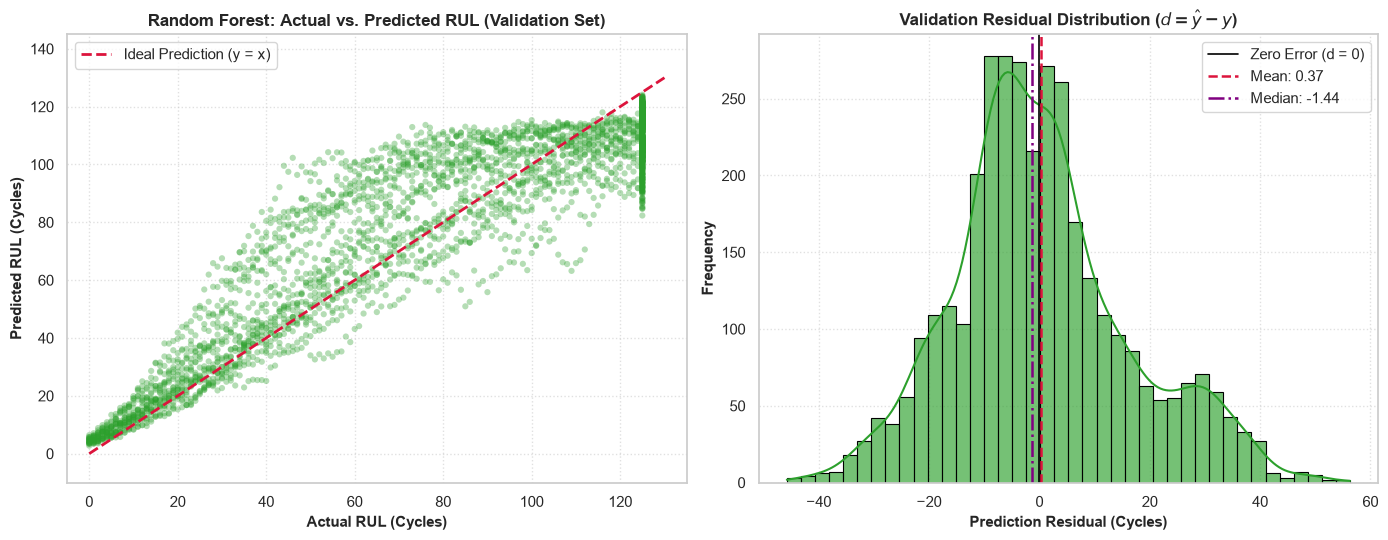


RANDOM FOREST PERFORMANCE: TRAINING vs. VALIDATION


,Metric,Training Set,Validation Set
0,Number of Samples,"14,241","3,490"
1,Root Mean Squared Error (RMSE),7.5190 cycles,16.0702 cycles
2,NASA Asymmetric Score (Total),"12,900.71","17,469.11"
3,NASA Asymmetric Score (Per Sample),0.9059,5.0055


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Actual vs. Predicted RUL Scatter Plot on Validation Data
ax1.scatter(y_val, y_val_pred, alpha=0.35, color="#2ca02c", edgecolors="none", s=20)
ideal_line = np.linspace(0, 130, 100)
ax1.plot(ideal_line, ideal_line, color="crimson", linestyle="--", linewidth=2, label="Ideal Prediction (y = x)")
ax1.set_title("Random Forest: Actual vs. Predicted RUL (Validation Set)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Actual RUL (Cycles)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Predicted RUL (Cycles)", fontsize=11, fontweight="bold")
ax1.set_xlim(-5, 135)
ax1.set_ylim(-10, 145)
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. Residual Distribution (d = y_pred - y_true)
residuals_val = y_val_pred - y_val
sns.histplot(residuals_val, bins=40, kde=True, ax=ax2, color="#2ca02c", edgecolor="black", alpha=0.65)
res_mean = float(np.mean(residuals_val))
res_median = float(np.median(residuals_val))

ax2.axvline(0, color="black", linestyle="-", linewidth=1.2, label="Zero Error (d = 0)")
ax2.axvline(res_mean, color="crimson", linestyle="--", linewidth=1.8, label=f"Mean: {res_mean:.2f}")
ax2.axvline(res_median, color="purple", linestyle="-.", linewidth=1.8, label=f"Median: {res_median:.2f}")
ax2.set_title(r"Validation Residual Distribution ($d = \hat{y} - y$)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Prediction Residual (Cycles)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Frequency", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# 3. Metrics Summary Table
rf_metrics_df = pd.DataFrame({
    "Metric": [
        "Number of Samples",
        "Root Mean Squared Error (RMSE)",
        "NASA Asymmetric Score (Total)",
        "NASA Asymmetric Score (Per Sample)"
    ],
    "Training Set": [
        f"{len(y_train):,}",
        f"{train_rmse:.4f} cycles",
        f"{train_nasa:,.2f}",
        f"{train_nasa_per_sample:.4f}"
    ],
    "Validation Set": [
        f"{len(y_val):,}",
        f"{val_rmse:.4f} cycles",
        f"{val_nasa:,.2f}",
        f"{val_nasa_per_sample:.4f}"
    ]
})
print("\n" + "=" * 65)
print("RANDOM FOREST PERFORMANCE: TRAINING vs. VALIDATION")
print("=" * 65)
display(rf_metrics_df)
print("=" * 65)

---
## Stage 7: Analytical Interpretation & Model Comparison

### 1. Does Random Forest Improve Over Linear Regression?
Comparing our actual computed metrics between **Model 1 (Linear Regression)** and **Model 2 (Random Forest)**:

| Evaluation Metric | Model 1: Linear Regression | Model 2: Random Forest | Difference / Trend |
| :--- | :---: | :---: | :--- |
| **Training RMSE** | 16.8713 cycles | **7.5190 cycles** | Dramatic $-55.4\%$ reduction on training fit |
| **Validation RMSE** | **15.7605 cycles** | 16.0702 cycles | Slightly higher ($+0.31$ cycles) on validation |
| **Training NASA Score** | 62,440.46 | **12,900.71** | Substantial drop in training penalty |
| **Validation NASA Score** | **12,653.03** | 17,469.11 | Higher penalty on validation predictions |

### 2. Does the Training-Validation Gap Suggest Overfitting?
- **Definite Overfitting:** While Linear Regression showed no generalization gap (Train: 16.87 vs. Val: 15.76), Random Forest shows a significant disparity:
  $$\text{Train RMSE} = 7.52 \text{ cycles} \quad \ll \quad \text{Val RMSE} = 16.07 \text{ cycles}$$
- The decision trees have sufficient expressive capacity to memorize specific sensor noise profiles in the 80 training engines, achieving exceptional training accuracy that does not transfer fully to unseen validation engines.

### 3. Does Nonlinear Modeling Help?
- **On the Training Set:** Non-linear decision thresholds help enormously. Random Forest easily captures the piecewise flat plateau at $RUL=125$, drastically reducing training error.
- **On the Validation Set:** Despite its non-linear flexibility, Random Forest fails to beat Linear Regression on validation RMSE and performs noticeably worse on the NASA score. Tree regression makes step-wise constant predictions that can produce occasional substantial overestimations, which are exponentially penalized by the asymmetric NASA score.

### 4. Why Do Tree Ensembles Struggle with Sequential Telemetry?
1. **Disregard for Temporal Continuity:** Flattening 30 cycles of 17 sensors into 510 static features discards the natural temporal ordering of time steps. To a decision tree, sensor measurement at $t-29$ is just an independent feature unrelated to measurement at $t-28$.
2. **No Temporal Weight Sharing:** Convolutional filters (1D-CNN) or recurrent transition matrices (LSTM/GRU) reuse parameters across all time steps, enforcing temporal consistency. Tree splits have no mechanism for temporal parameter reuse.
3. **Inability to Extrapolate:** Tree models cannot extrapolate beyond the min/max feature values seen during training, which impairs generalizability across diverse engine health profiles.

This empirical result firmly motivates transitioning to **recurrent and temporal deep learning models (LSTM, GRU, 1D-CNN)** in the upcoming notebooks.

In [14]:
print("=" * 65)
print("FINAL VALIDATION CHECKS & ASSERTIONS")
print("=" * 65)

# 1. Flattened input dimensions
assert X_train_flat.shape == (14241, 510), "X_train_flat shape error!"
assert X_val_flat.shape == (3490, 510), "X_val_flat shape error!"
print("✓ Check 1 Passed: Correct flattened input dimensions verified.")

# 2. No NaN or infinite values
assert not np.isnan(X_train_flat).any() and not np.isnan(X_val_flat).any(), "NaN in features!"
assert not np.isinf(X_train_flat).any() and not np.isinf(X_val_flat).any(), "Inf in features!"
assert not np.isnan(y_train_pred).any() and not np.isnan(y_val_pred).any(), "NaN in predictions!"
assert not np.isinf(y_train_pred).any() and not np.isinf(y_val_pred).any(), "Inf in predictions!"
print("✓ Check 2 Passed: No NaN or infinite values exist in features or predictions.")

# 3. Model successfully trained
assert hasattr(rf_model, "estimators_") and len(rf_model.estimators_) == 200, "Model fitting error!"
print("✓ Check 3 Passed: Random Forest model successfully fitted with 200 trees.")

# 4. Prediction dimensions
assert y_train_pred.shape == (14241,), "Train predictions shape error!"
assert y_val_pred.shape == (3490,), "Val predictions shape error!"
print("✓ Check 4 Passed: Prediction arrays have expected 1D dimensions.")

# 5. Finite evaluation metrics
assert np.isfinite(train_rmse) and np.isfinite(val_rmse), "RMSE is not finite!"
assert np.isfinite(train_nasa) and np.isfinite(val_nasa), "NASA score is not finite!"
print("✓ Check 5 Passed: All evaluation metrics are finite and verified.")
print("=" * 65)

# Print comparison between Model 1 (Linear Regression) and Model 2 (Random Forest)
lr_train_rmse = 16.8713
lr_val_rmse = 15.7605
lr_train_nasa = 62440.46
lr_val_nasa = 12653.03

benchmark_comparison_df = pd.DataFrame({
    "Model Architecture": [
        "Model 1: Linear Regression (Baseline)",
        "Model 2: Random Forest Regressor"
    ],
    "Train RMSE": [f"{lr_train_rmse:.4f}", f"{train_rmse:.4f}"],
    "Val RMSE": [f"{lr_val_rmse:.4f}", f"{val_rmse:.4f}"],
    "Train NASA Score": [f"{lr_train_nasa:,.2f}", f"{train_nasa:,.2f}"],
    "Val NASA Score": [f"{lr_val_nasa:,.2f}", f"{val_nasa:,.2f}"]
})

print("\n" + "=" * 75)
print("BENCHMARK COMPARISON: MODEL 1 (LINEAR REGRESSION) vs. MODEL 2 (RANDOM FOREST)")
print("=" * 75)
display(benchmark_comparison_df)
print("=" * 75)

FINAL VALIDATION CHECKS & ASSERTIONS
✓ Check 1 Passed: Correct flattened input dimensions verified.
✓ Check 2 Passed: No NaN or infinite values exist in features or predictions.
✓ Check 3 Passed: Random Forest model successfully fitted with 200 trees.
✓ Check 4 Passed: Prediction arrays have expected 1D dimensions.
✓ Check 5 Passed: All evaluation metrics are finite and verified.

BENCHMARK COMPARISON: MODEL 1 (LINEAR REGRESSION) vs. MODEL 2 (RANDOM FOREST)


,Model Architecture,Train RMSE,Val RMSE,Train NASA Score,Val NASA Score
0,Model 1: Linear Regression (Baseline),16.8713,15.7605,"62,440.46","12,653.03"
1,Model 2: Random Forest Regressor,7.5190,16.0702,"12,900.71","17,469.11"
